# Bloch2D validation: band curvature and two-dimensional density of states

**Part I of the semiconductor-physics long assessment**

This notebook uses the maintained PhysKit `CheckerboardPotentialBloch2D` implementation to validate the chain

$$
H(\mathbf{k})\rightarrow E_n(\mathbf{k})\rightarrow \mathbf{M}^{*-1}
\rightarrow g_{2D}(E).
$$

The calculation is an idealized **two-dimensional** square-lattice model. Its DOS has units of states eV$^{-1}$ area$^{-1}$; it is not the three-dimensional DOS of the bulk material used later in the assessment. Transport is deliberately excluded.

Run from a clean kernel after installing the pinned dependencies in the repository `requirements.txt`.


## What is supplied and what is implemented here

**Supplied by PhysKit (release 0.1.2, repository commit pinned in `requirements.txt`):**

- unit-aware `BlochCell2D` direct and reciprocal lattices;
- the checkerboard potential and its reciprocal-space Fourier operator;
- construction and diagonalization of the plane-wave Bloch Hamiltonian;
- high-symmetry paths and normalized full-zone 2D DOS estimation.

**Implemented in this notebook:**

- the standard class parameter choice and convergence controls;
- Hermiticity and reciprocal-basis checks;
- independent path and uniform-zone calculations;
- numerical edge search and classification;
- local quadratic regression, principal masses, directional residuals, and fit-window convergence;
- treatment of the symmetry-folded conduction doublet; and
- comparison of the mesh DOS with the analytic anisotropic parabolic DOS.


In [1]:
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.constants import Boltzmann, electron_mass, electron_volt, hbar
from scipy.optimize import brentq, minimize

from projectkoios.physkit.dos2d.model import UniformBandDensityOfStates2D
from projectkoios.physkit.periodic.kpoints import KPointPath2D
from projectkoios.physkit.solidstate.bloch2d.cell import BlochCell2D
from projectkoios.physkit.solidstate.bloch2d.checkerboard.model import (
    CheckerboardPotentialBloch2D,
)
from projectkoios.physkit.units import (
    MatrixQuantity,
    PhysicalUnit,
    ScalarQuantity,
    UnitSystem,
    VectorQuantity,
)

plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.22})
pd.options.display.float_format = "{:,.7g}".format

print("projectkoios-physkit", version("projectkoios-physkit"))


projectkoios-physkit 0.1.2


## 1. Physical model, lattice, and representation

The standard class model is a bare electron of mass $m_0$ in

$$
V(x,y)=V_0\cos(2\pi x/a)\cos(2\pi y/a),
\qquad a=5.43\ \text{Å},\quad V_0=4.0\ \text{eV}.
$$

The displayed square cell has direct basis $A=(a\mathbf e_x,a\mathbf e_y)$ and reciprocal basis $B=2\pi A^{-\mathsf T}$. The cell-periodic factor satisfies $u_{n\mathbf k}(\mathbf r+\mathbf a_i)=u_{n\mathbf k}(\mathbf r)$, while the full Bloch state obeys $\psi_{n\mathbf k}(\mathbf r+\mathbf a_i)=e^{i\mathbf k\cdot\mathbf a_i}\psi_{n\mathbf k}(\mathbf r)$.

PhysKit expands $u_{n\mathbf k}$ in plane waves $|\mathbf k+\mathbf G\rangle$ with $-M\le m_1,m_2\le M$:

$$
H_{\mathbf G\mathbf G'}(\mathbf k)=
\frac{\hbar^2|\mathbf k+\mathbf G|^2}{2m_0}\delta_{\mathbf G\mathbf G'}
+V_{\mathbf G-\mathbf G'}.
$$

For the checkerboard potential, $V_{\pm\mathbf b_1\pm\mathbf b_2}=V_0/4$ and all other nonzero-frequency coefficients vanish. With $M=3$, the represented Hamiltonian has $(2M+1)^2=49$ basis functions. Energies are in eV and wave vectors in Å$^{-1}$.


In [2]:
# Standard class parameters
lattice_constant_angstrom = 5.43
potential_amplitude_ev = 4.0
reciprocal_mode_limit = 3
band_count = 6
valence_band_index = 1       # zero-based band 2
conduction_band_indices = (2, 3)  # folded, degenerate bands 3 and 4
spin_degeneracy = 2.0
full_zone_axis_count = 48

cell = BlochCell2D(
    direct_basis=MatrixQuantity(
        lattice_constant_angstrom * np.eye(2),
        UnitSystem.METAL.length_unit,
    ),
    unit_system=UnitSystem.METAL,
)
model = CheckerboardPotentialBloch2D(
    cell=cell,
    amplitude=ScalarQuantity(
        potential_amplitude_ev, UnitSystem.METAL.energy_unit
    ),
)
reciprocal_unit = cell.reciprocal_basis.unit
zone_edge = np.pi / lattice_constant_angstrom
zone_width = 2.0 * zone_edge

lattice_table = pd.DataFrame(
    {
        "quantity": ["a1", "a2", "b1", "b2", "cell area", "BZ area"],
        "components/value": [
            cell.direct_basis.magnitude[:, 0],
            cell.direct_basis.magnitude[:, 1],
            cell.reciprocal_basis.magnitude[:, 0],
            cell.reciprocal_basis.magnitude[:, 1],
            cell.area.magnitude,
            zone_width**2,
        ],
        "unit": ["angstrom", "angstrom", "1/angstrom", "1/angstrom", "angstrom^2", "1/angstrom^2"],
    }
)
lattice_table


,quantity,components/value,unit
0,a1,"[5.43, 0.0]",angstrom
1,a2,"[0.0, 5.43]",angstrom
2,b1,"[1.1571243659630914, 0.0]",1/angstrom
3,b2,"[0.0, 1.1571243659630914]",1/angstrom
4,cell area,29.4849,angstrom^2
5,BZ area,1.338937,1/angstrom^2


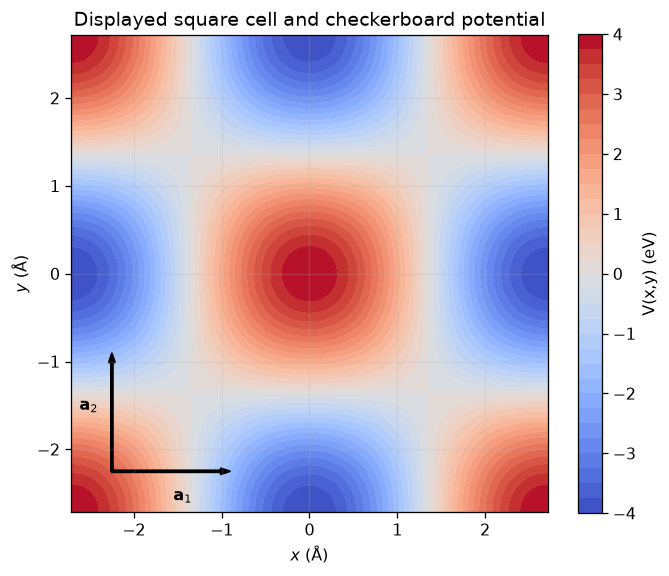

In [3]:
# Unit cell and periodic potential
coordinate = np.linspace(-0.5 * lattice_constant_angstrom,
                         0.5 * lattice_constant_angstrom, 241)
x_grid, y_grid = np.meshgrid(coordinate, coordinate, indexing="ij")
potential_ev = potential_amplitude_ev * np.cos(
    2.0 * np.pi * x_grid / lattice_constant_angstrom
) * np.cos(2.0 * np.pi * y_grid / lattice_constant_angstrom)

fig, ax = plt.subplots(figsize=(6.0, 5.0))
image = ax.contourf(x_grid, y_grid, potential_ev, levels=31, cmap="coolwarm")
fig.colorbar(image, ax=ax, label="V(x,y) (eV)")
ax.arrow(-2.25, -2.25, 1.35, 0, width=0.025, color="k", length_includes_head=True)
ax.arrow(-2.25, -2.25, 0, 1.35, width=0.025, color="k", length_includes_head=True)
ax.text(-1.55, -2.58, r"$\mathbf{a}_1$")
ax.text(-2.62, -1.55, r"$\mathbf{a}_2$")
ax.set(xlabel=r"$x$ (Å)", ylabel=r"$y$ (Å)",
       title="Displayed square cell and checkerboard potential", aspect="equal")
fig.tight_layout()


### Hermiticity test

A generic off-symmetry wave vector is used so the test is not accidentally restricted to a special point. The normalized residual is

$$
r_H=\frac{\|H-H^\dagger\|_F}{\max(\|H\|_F,\epsilon)}.
$$


In [4]:
probe_k = np.array([0.173, -0.219]) * zone_edge
represented = model.construct_hamiltonian(
    bloch_wave_vector=VectorQuantity(probe_k, reciprocal_unit),
    reciprocal_mode_limit=reciprocal_mode_limit,
)
h_matrix = represented.represented_hamiltonian.to_csr().toarray()
hermiticity_residual = np.linalg.norm(h_matrix - h_matrix.conj().T) / np.linalg.norm(h_matrix)

pd.Series(
    {
        "basis size": h_matrix.shape[0],
        "max |Im(H)| (eV)": np.max(np.abs(h_matrix.imag)),
        "normalized Hermiticity residual": hermiticity_residual,
    },
    name="Hamiltonian check",
)


basis size                        49
max |Im(H)| (eV)                   0
normalized Hermiticity residual    0
Name: Hamiltonian check, dtype: float64

## 2. High-symmetry path and full two-dimensional zone

The path $\Gamma-X-M-\Gamma$ is only a one-dimensional visualization and has zero area in the Brillouin zone. All edge searches and DOS state counting below use a separate uniform, endpoint-excluded two-dimensional mesh.


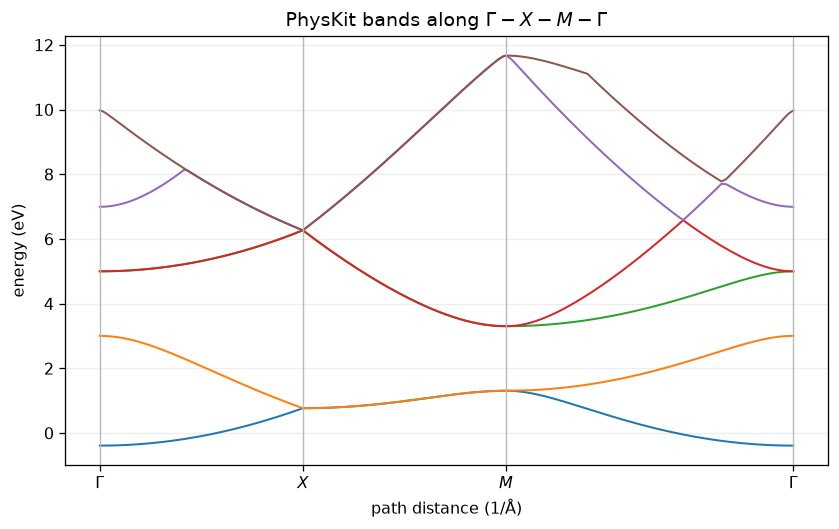

In [5]:
path = KPointPath2D(
    nodes=np.array([[0.0, 0.0], [zone_edge, 0.0],
                    [zone_edge, zone_edge], [0.0, 0.0]]),
    labels=(r"$\Gamma$", r"$X$", r"$M$", r"$\Gamma$"),
    points_per_segment=61,
)
path_result = model.solve_bands(
    bloch_wave_vectors=MatrixQuantity(path.values, reciprocal_unit),
    reciprocal_mode_limit=reciprocal_mode_limit,
    band_count=band_count,
)

fig, ax = plt.subplots(figsize=(7.4, 4.7))
for band in range(band_count):
    ax.plot(path.distances, path_result.energies.magnitude[:, band], lw=1.25)
for node_distance in path.node_distances:
    ax.axvline(node_distance, color="0.72", lw=0.8)
ax.set_xticks(path.node_distances, path.labels)
ax.set(xlabel="path distance (1/Å)", ylabel="energy (eV)",
       title=r"PhysKit bands along $\Gamma-X-M-\Gamma$")
fig.tight_layout()


In [6]:
# Unique equal-weight samples on [-pi/a, pi/a)^2.
k_axis = np.linspace(-zone_edge, zone_edge, full_zone_axis_count, endpoint=False)
kx_grid, ky_grid = np.meshgrid(k_axis, k_axis, indexing="ij")
full_zone_vectors = np.column_stack((kx_grid.ravel(), ky_grid.ravel()))
full_zone_result = model.solve_bands(
    bloch_wave_vectors=MatrixQuantity(full_zone_vectors, reciprocal_unit),
    reciprocal_mode_limit=reciprocal_mode_limit,
    band_count=band_count,
)
full_zone_bands_ev = full_zone_result.energies.magnitude

def fold_to_zone(k):
    """Map a Cartesian wave vector into [-pi/a, pi/a)."""
    return (np.asarray(k) + zone_edge) % zone_width - zone_edge


def solve_energies(k_vectors, count=4):
    return model.solve_bands(
        bloch_wave_vectors=MatrixQuantity(np.atleast_2d(k_vectors), reciprocal_unit),
        reciprocal_mode_limit=reciprocal_mode_limit,
        band_count=count,
    ).energies.magnitude

# Discrete full-zone candidates.
valence_values = full_zone_bands_ev[:, valence_band_index]
conduction_values = np.min(full_zone_bands_ev[:, conduction_band_indices], axis=1)
v_mesh_index = int(np.argmax(valence_values))
c_mesh_index = int(np.argmin(conduction_values))
k_v_mesh = full_zone_vectors[v_mesh_index]
k_c_mesh = full_zone_vectors[c_mesh_index]

# Local periodic refinement; this verifies rather than assumes the special points.
v_refinement = minimize(
    lambda q: -solve_energies(fold_to_zone(k_v_mesh + q))[0, valence_band_index],
    np.zeros(2), method="Nelder-Mead", options={"xatol": 1e-11, "fatol": 1e-12},
)
c_refinement = minimize(
    lambda q: np.min(solve_energies(fold_to_zone(k_c_mesh + q))[0, 2:4]),
    np.zeros(2), method="Nelder-Mead", options={"xatol": 1e-11, "fatol": 1e-12},
)
k_v = fold_to_zone(k_v_mesh + v_refinement.x)
k_c = fold_to_zone(k_c_mesh + c_refinement.x)
valence_edge_ev = float(solve_energies(k_v)[0, valence_band_index])
conduction_pair_at_edge = solve_energies(k_c)[0, 2:4]
conduction_edge_ev = float(np.min(conduction_pair_at_edge))
band_gap_ev = conduction_edge_ev - valence_edge_ev

edge_table = pd.DataFrame(
    [
        {"edge": "valence maximum", "band(s), 1-based": "2",
         "kx (1/angstrom)": k_v[0], "ky (1/angstrom)": k_v[1],
         "energy (eV)": valence_edge_ev,
         "classification": "isolated k point; nondegenerate eigenvalue"},
        {"edge": "conduction minimum", "band(s), 1-based": "3-4",
         "kx (1/angstrom)": k_c[0], "ky (1/angstrom)": k_c[1],
         "energy (eV)": conduction_edge_ev,
         "classification": "isolated modulo BZ; two folded symmetry-equivalent sheets"},
    ]
)
assert band_gap_ev > 0
edge_table


,edge,"band(s), 1-based",kx (1/angstrom),ky (1/angstrom),energy (eV),classification
0,valence maximum,2,0,0,3.008024,isolated k point; nondegenerate eigenvalue
1,conduction minimum,3-4,-0.5785622,-0.5785622,3.30638,isolated modulo BZ; two folded symmetry-equiva...


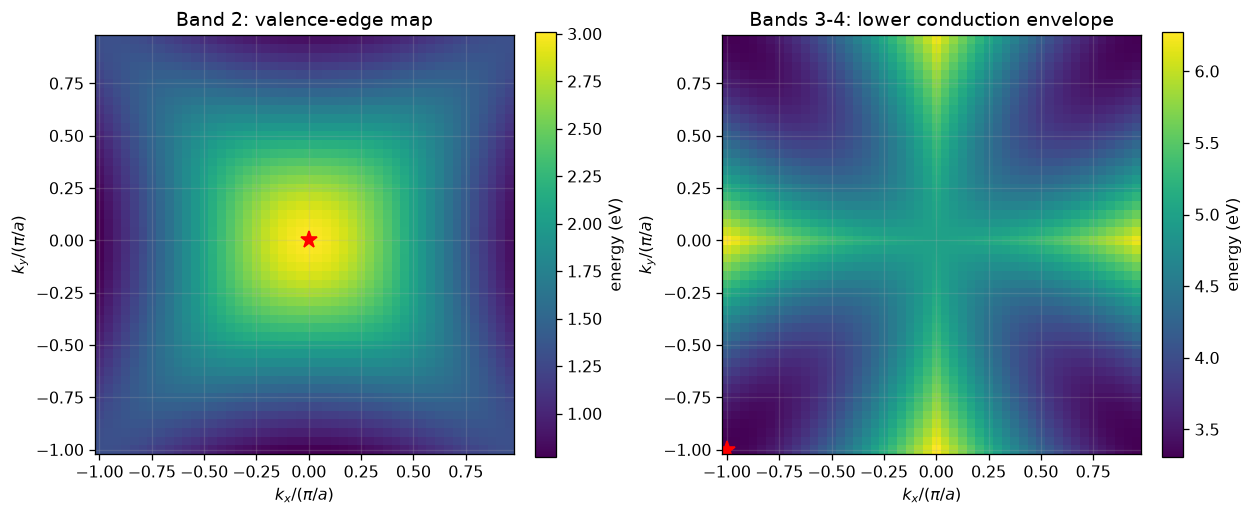

In [7]:
valence_map = valence_values.reshape(full_zone_axis_count, full_zone_axis_count)
conduction_map = conduction_values.reshape(full_zone_axis_count, full_zone_axis_count)

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.4), constrained_layout=True)
for ax, values, title, marker in [
    (axes[0], valence_map, "Band 2: valence-edge map", k_v),
    (axes[1], conduction_map, "Bands 3-4: lower conduction envelope", k_c),
]:
    image = ax.pcolormesh(k_axis / zone_edge, k_axis / zone_edge, values.T,
                          shading="auto", cmap="viridis")
    ax.plot(marker[0] / zone_edge, marker[1] / zone_edge, "r*", ms=11)
    fig.colorbar(image, ax=ax, label="energy (eV)")
    ax.set(xlabel=r"$k_x/(\pi/a)$", ylabel=r"$k_y/(\pi/a)$",
           title=title, aspect="equal")


### Important folding classification

The displayed square cell is not primitive for this product potential: a simultaneous half-cell translation leaves $V$ unchanged. Consequently, bands 3 and 4 are exactly degenerate at the represented $M$ point. Sorting eigenvalues independently at each $\mathbf k$ produces a lower envelope that is not one differentiable band sheet. Blindly fitting only “band 3” would therefore return a direction-dependent, non-Hessian curvature.

The two smooth sheets can be reconstructed locally from the sorted pair. For sheet A we select the lower eigenvalue when $q_xq_y>0$, the upper eigenvalue when $q_xq_y<0$, and their mean on an axis. Sheet B uses the complementary choice and is related by square symmetry. Both sheets have the same DOS mass, with principal axes interchanged; therefore the conduction valley/sheet degeneracy used in the analytic DOS is $g_v=2$. This reconstruction is a notebook extension, not hidden behavior of the PhysKit eigensolver.


## 3. Separate numerical error checks

1. **Reciprocal-basis error:** increase the plane-wave cutoff $M$ at the refined edge points.
2. **$\mathbf k$-mesh error:** use deliberately cell-centered grids that miss both $\Gamma$ and $M$, then compare their sampled extrema with the refined values.
3. **Fit-window drift:** repeat the quadratic fit over four radii. Residual growth and mass drift after basis and mesh checks are evidence of physical nonparabolicity over the larger window.


In [8]:
# Plane-wave basis convergence at the located edges.
basis_rows = []
for mode_limit in (2, 3, 4):
    result = model.solve_bands(
        bloch_wave_vectors=MatrixQuantity(np.vstack((k_v, k_c)), reciprocal_unit),
        reciprocal_mode_limit=mode_limit,
        band_count=4,
    ).energies.magnitude
    basis_rows.append({
        "M": mode_limit,
        "basis size": (2 * mode_limit + 1) ** 2,
        "Ev (eV)": result[0, 1],
        "Ec (eV)": np.min(result[1, 2:4]),
        "Eg (eV)": np.min(result[1, 2:4]) - result[0, 1],
    })
basis_convergence = pd.DataFrame(basis_rows)
basis_convergence


,M,basis size,Ev (eV),Ec (eV),Eg (eV)
0,2,25,3.008295,3.307329,0.2990341
1,3,49,3.008024,3.30638,0.2983565
2,4,81,3.008024,3.306379,0.2983553


In [9]:
# Cell-centered meshes intentionally omit the exact extrema.
mesh_rows = []
for axis_count in (18, 26, 34):
    shifted_axis = -zone_edge + (np.arange(axis_count) + 0.5) * zone_width / axis_count
    sx, sy = np.meshgrid(shifted_axis, shifted_axis, indexing="ij")
    vectors = np.column_stack((sx.ravel(), sy.ravel()))
    energies = solve_energies(vectors)
    ev_sample = np.max(energies[:, valence_band_index])
    ec_sample = np.min(energies[:, 2:4])
    mesh_rows.append({
        "axis count": axis_count,
        "delta k (1/angstrom)": zone_width / axis_count,
        "Ev error (meV)": 1e3 * (ev_sample - valence_edge_ev),
        "Ec error (meV)": 1e3 * (ec_sample - conduction_edge_ev),
    })
mesh_convergence = pd.DataFrame(mesh_rows)
mesh_convergence


,axis count,delta k (1/angstrom),Ev error (meV),Ec error (meV)
0,18,0.06428469,-32.00349,7.303452
1,26,0.04450478,-15.53364,3.500837
2,34,0.03403307,-9.12844,2.047271


## 4. Local quadratic fits and effective-mass tensors

For $\mathbf q=\mathbf k-\mathbf k_0$, the regression basis is

$$
E(\mathbf q)=c+\ell_xq_x+\ell_yq_y+	frac12H_{xx}q_x^2
+H_{xy}q_xq_y+	frac12H_{yy}q_y^2.
$$

The electronic Hessian $H$ is converted using

$$
\frac{M^{-1}_{ij}}{m_0^{-1}}=\frac{H_{ij}}{\hbar^2/m_0}.
$$

For the valence maximum the positive hole tensor uses $-H$. Here $\hbar^2/m_0=7.619964\ \text{eV Å}^2$. The smallest-radius result is sensitive to numerical differentiation, while a large radius mixes in nonparabolicity; $r=0.03$ Å$^{-1}$ is used for the reported local tensor and the other radii quantify drift.


In [10]:
HBAR2_OVER_M0_EV_A2 = (hbar**2 / electron_mass) / electron_volt / 1e-20


def disk_offsets(radius, points_per_axis=11):
    axis = np.linspace(-radius, radius, points_per_axis)
    q = np.array([(x, y) for x in axis for y in axis
                  if x*x + y*y <= radius*radius + 1e-15])
    return q


def conduction_sheet_a(q):
    """Reconstruct one smooth member of the folded bands 3-4 doublet."""
    q = np.atleast_2d(q)
    energies = solve_energies(fold_to_zone(k_c + q))[:, 2:4]
    product = q[:, 0] * q[:, 1]
    selected = np.where(product > 1e-15, energies[:, 0], energies[:, 1])
    on_axis = np.abs(product) <= 1e-15
    selected[on_axis] = np.mean(energies[on_axis], axis=1)
    return selected


def edge_samples(kind, q):
    if kind == "valence":
        return solve_energies(fold_to_zone(k_v + q))[:, valence_band_index]
    if kind == "conduction":
        return conduction_sheet_a(q)
    raise ValueError(kind)


def fit_quadratic(kind, radius):
    q = disk_offsets(radius)
    energy = edge_samples(kind, q)
    design = np.column_stack((
        np.ones(len(q)), q[:, 0], q[:, 1],
        0.5*q[:, 0]**2, q[:, 0]*q[:, 1], 0.5*q[:, 1]**2,
    ))
    coefficients, *_ = np.linalg.lstsq(design, energy, rcond=None)
    fitted = design @ coefficients
    electronic_hessian = np.array([
        [coefficients[3], coefficients[4]],
        [coefficients[4], coefficients[5]],
    ])
    positive_hessian = -electronic_hessian if kind == "valence" else electronic_hessian
    curvatures, directions = np.linalg.eigh(positive_hessian)
    # An isotropic tensor has no unique principal axes; report x and y rather
    # than numerical eigensolver directions selected by roundoff.
    if np.ptp(curvatures) <= 1e-9 * np.max(np.abs(curvatures)):
        directions = np.eye(2)
    masses_m0 = HBAR2_OVER_M0_EV_A2 / curvatures
    residual = fitted - energy
    edge_energy = valence_edge_ev if kind == "valence" else conduction_edge_ev
    return {
        "kind": kind, "radius": radius, "q": q, "energy": energy,
        "coefficients": coefficients, "electronic_hessian": electronic_hessian,
        "positive_hessian": positive_hessian, "curvatures": curvatures,
        "directions": directions, "masses_m0": masses_m0,
        "rmse_ev": np.sqrt(np.mean(residual**2)),
        "max_error_ev": np.max(np.abs(residual)),
        "energy_window_ev": np.max(np.abs(energy - edge_energy)),
    }

fit_radii = (0.015, 0.030, 0.060, 0.100)
fits = {(kind, radius): fit_quadratic(kind, radius)
        for kind in ("valence", "conduction") for radius in fit_radii}
fit_rows = []
for (kind, radius), result in fits.items():
    fit_rows.append({
        "edge": kind, "radius (1/angstrom)": radius,
        "max |E-Eedge| (meV)": 1e3 * result["energy_window_ev"],
        "m1/m0": result["masses_m0"][0], "m2/m0": result["masses_m0"][1],
        "RMSE (meV)": 1e3 * result["rmse_ev"],
        "max residual (meV)": 1e3 * result["max_error_ev"],
    })
fit_convergence = pd.DataFrame(fit_rows)
fit_convergence


,edge,radius (1/angstrom),max |E-Eedge| (meV),m1/m0,m2/m0,RMSE (meV),max residual (meV)
0,valence,0.015,3.566624,0.2405821,0.2405821,0.001205143,0.002627326
1,valence,0.03,14.20829,0.2422504,0.2422504,0.01893838,0.04122273
2,valence,0.06,55.93147,0.248795,0.248795,0.282843,0.6120085
3,valence,0.1,149.8982,0.2636087,0.2636087,1.884654,4.02806
4,conduction,0.015,5.178712,1.078033,0.1626764,0.0007635416,0.002218759
5,conduction,0.03,20.60402,1.078804,0.1634217,0.01191755,0.0345457
6,conduction,0.06,80.75108,1.081899,0.1663075,0.1776831,0.5111525
7,conduction,0.1,214.8787,1.088331,0.1726526,1.18196,3.346789


In [11]:
# Tensor components and principal directions for the selected local window.
reported_radius = 0.030
tensor_rows = []
for kind in ("valence", "conduction"):
    result = fits[(kind, reported_radius)]
    inverse_mass_m0 = result["positive_hessian"] / HBAR2_OVER_M0_EV_A2
    for principal in range(2):
        tensor_rows.append({
            "edge": kind,
            "fit radius (1/angstrom)": reported_radius,
            "Hxx (eV angstrom^2)": result["positive_hessian"][0, 0],
            "Hxy (eV angstrom^2)": result["positive_hessian"][0, 1],
            "Hyy (eV angstrom^2)": result["positive_hessian"][1, 1],
            "(M^-1)xx (1/m0)": inverse_mass_m0[0, 0],
            "(M^-1)xy (1/m0)": inverse_mass_m0[0, 1],
            "(M^-1)yy (1/m0)": inverse_mass_m0[1, 1],
            "principal": principal + 1,
            "mass (m0)": result["masses_m0"][principal],
            "direction x": result["directions"][0, principal],
            "direction y": result["directions"][1, principal],
        })
tensor_table = pd.DataFrame(tensor_rows)
tensor_table


,edge,fit radius (1/angstrom),Hxx (eV angstrom^2),Hxy (eV angstrom^2),Hyy (eV angstrom^2),(M^-1)xx (1/m0),(M^-1)xy (1/m0),(M^-1)yy (1/m0),principal,mass (m0),direction x,direction y
0,valence,0.03,31.4549,5.554881e-12,31.4549,4.127959,7.289904e-13,4.127959,1,0.2422504,1,0
1,valence,0.03,31.4549,5.554881e-12,31.4549,4.127959,7.289904e-13,4.127959,2,0.2422504,0,1
2,conduction,0.03,26.84548,-19.78213,26.84548,3.523045,-2.596092,3.523045,1,1.078804,-0.7071068,-0.7071068
3,conduction,0.03,26.84548,-19.78213,26.84548,3.523045,-2.596092,3.523045,2,0.1634217,-0.7071068,0.7071068


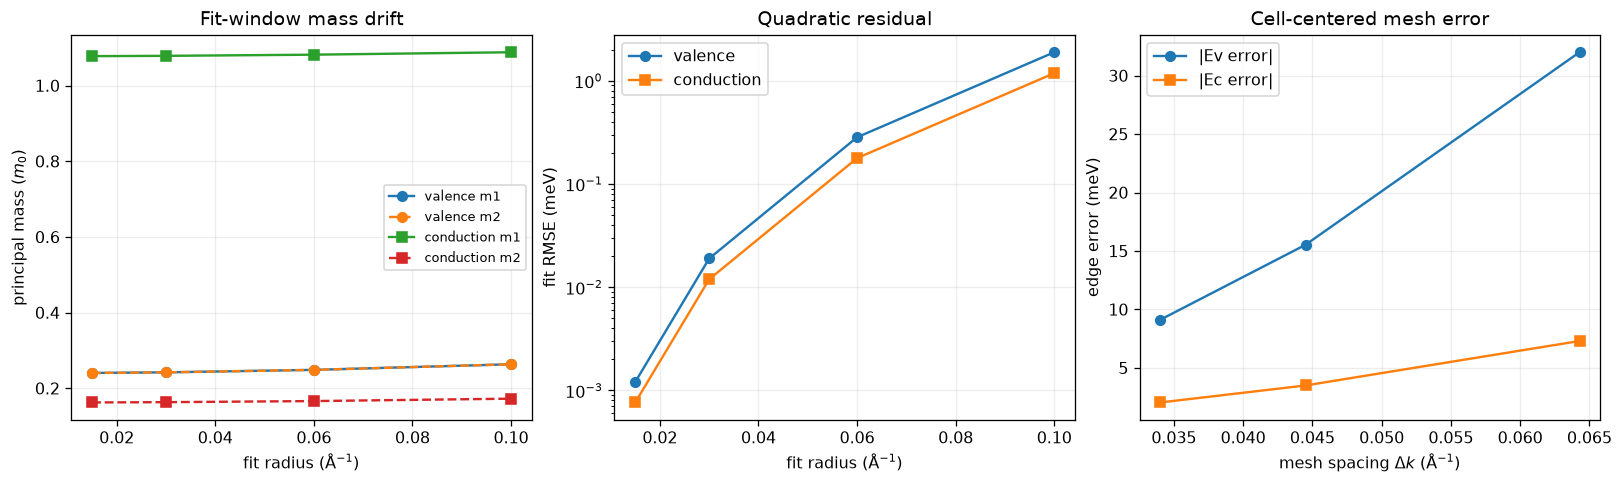

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.1), constrained_layout=True)
for kind, marker in (("valence", "o"), ("conduction", "s")):
    block = fit_convergence[fit_convergence["edge"] == kind]
    axes[0].plot(block["radius (1/angstrom)"], block["m1/m0"], marker=marker,
                 label=f"{kind} m1")
    axes[0].plot(block["radius (1/angstrom)"], block["m2/m0"], marker=marker,
                 ls="--", label=f"{kind} m2")
    axes[1].semilogy(block["radius (1/angstrom)"], block["RMSE (meV)"],
                     marker=marker, label=kind)
axes[0].set(xlabel=r"fit radius (Å$^{-1}$)", ylabel=r"principal mass ($m_0$)",
            title="Fit-window mass drift")
axes[1].set(xlabel=r"fit radius (Å$^{-1}$)", ylabel="fit RMSE (meV)",
            title="Quadratic residual")
axes[0].legend(fontsize=8); axes[1].legend()
axes[2].plot(mesh_convergence["delta k (1/angstrom)"],
             np.abs(mesh_convergence["Ev error (meV)"]), "o-", label="|Ev error|")
axes[2].plot(mesh_convergence["delta k (1/angstrom)"],
             np.abs(mesh_convergence["Ec error (meV)"]), "s-", label="|Ec error|")
axes[2].set(xlabel=r"mesh spacing $\Delta k$ (Å$^{-1}$)", ylabel="edge error (meV)",
            title="Cell-centered mesh error")
axes[2].legend()


### Directional validation

Numerical energies are sampled along both principal directions of each reported tensor. The plotted parabola uses the full fitted constant, linear term, and tensor—not a second one-dimensional refit. Residuals therefore test the two-dimensional regression directly.


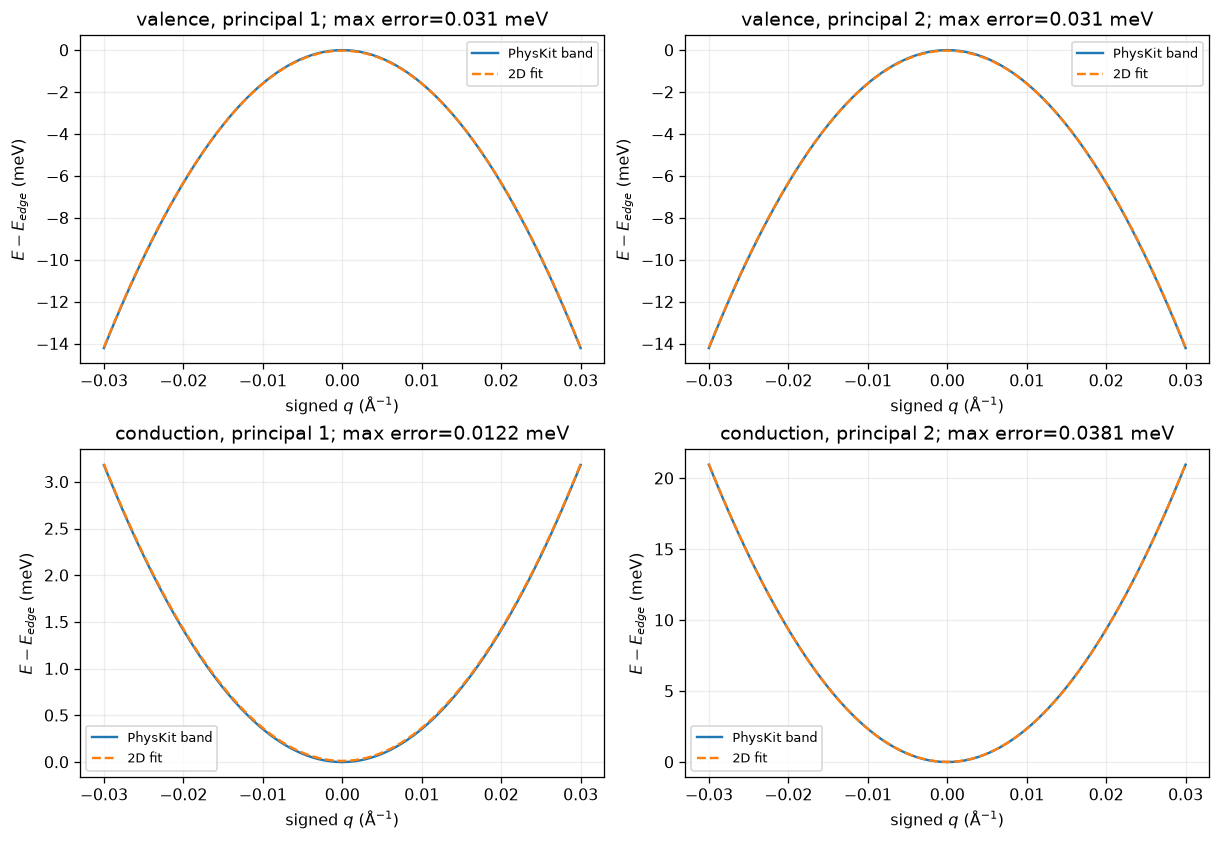

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2), constrained_layout=True)
line_coordinate = np.linspace(-reported_radius, reported_radius, 81)
for row, kind in enumerate(("valence", "conduction")):
    result = fits[(kind, reported_radius)]
    c = result["coefficients"]
    for principal in range(2):
        direction = result["directions"][:, principal]
        q = line_coordinate[:, None] * direction[None, :]
        numerical = edge_samples(kind, q)
        design = np.column_stack((
            np.ones(len(q)), q[:, 0], q[:, 1],
            0.5*q[:, 0]**2, q[:, 0]*q[:, 1], 0.5*q[:, 1]**2,
        ))
        parabola = design @ c
        reference = valence_edge_ev if kind == "valence" else conduction_edge_ev
        ax = axes[row, principal]
        ax.plot(line_coordinate, 1e3*(numerical-reference), label="PhysKit band")
        ax.plot(line_coordinate, 1e3*(parabola-reference), "--", label="2D fit")
        max_line_error = 1e3*np.max(np.abs(numerical-parabola))
        ax.set(xlabel=r"signed $q$ (Å$^{-1}$)", ylabel=r"$E-E_{edge}$ (meV)",
               title=f"{kind}, principal {principal+1}; max error={max_line_error:.3g} meV")
        ax.legend(fontsize=8)


## 5. Numerical and analytic two-dimensional DOS

PhysKit assigns every unique full-zone eigenvalue the state-density weight

$$
w=\frac{g_s A_{BZ}}{(2\pi)^2N_k}.
$$

Thus one complete band integrates to $g_s/a^2$ states Å$^{-2}$. Gaussian broadening is used only to display the numerical DOS; its finite tail below an edge is not a physical in-gap DOS.

For one anisotropic 2D parabolic valley,

$$
m_{d,2D}=\sqrt{m_1m_2},\qquad
 g_{2D}(E)=\frac{g_sg_vm_{d,2D}}{2\pi\hbar^2}\Theta(E-E_C).
$$

The conduction comparison uses both folded sheets ($g_v=2$). The valence comparison uses band 2 ($g_v=1$). Masses are from the $0.03$ Å$^{-1}$ fit.


In [14]:
energy_min = float(np.min(full_zone_bands_ev[:, 1:4])) - 0.08
energy_max = float(np.max(full_zone_bands_ev[:, 1:4])) + 0.08
energy_grid = VectorQuantity(
    np.linspace(energy_min, energy_max, 2400), UnitSystem.METAL.energy_unit
)
broadening = ScalarQuantity(0.010, UnitSystem.METAL.energy_unit)
dos_model = UniformBandDensityOfStates2D(
    brillouin_zone_measure=ScalarQuantity(
        zone_width**2, PhysicalUnit("1 / angstrom ** 2")
    ),
    state_degeneracy=float(spin_degeneracy),
)
valence_dos = dos_model.evaluate_gaussian(
    band_energies=MatrixQuantity(
        full_zone_bands_ev[:, valence_band_index:valence_band_index+1],
        UnitSystem.METAL.energy_unit,
    ),
    energy_grid=energy_grid,
    broadening=broadening,
)
conduction_dos = dos_model.evaluate_gaussian(
    band_energies=MatrixQuantity(
        full_zone_bands_ev[:, 2:4], UnitSystem.METAL.energy_unit
    ),
    energy_grid=energy_grid,
    broadening=broadening,
)

expected_per_band = spin_degeneracy / lattice_constant_angstrom**2
state_count_table = pd.DataFrame([
    {"manifold": "valence band 2", "bands": 1,
     "represented states (1/angstrom^2)": valence_dos.represented_state_density.magnitude,
     "Gaussian integral (1/angstrom^2)": valence_dos.integrated_state_density.magnitude,
     "expected (1/angstrom^2)": expected_per_band},
    {"manifold": "conduction bands 3-4", "bands": 2,
     "represented states (1/angstrom^2)": conduction_dos.represented_state_density.magnitude,
     "Gaussian integral (1/angstrom^2)": conduction_dos.integrated_state_density.magnitude,
     "expected (1/angstrom^2)": 2*expected_per_band},
])
state_count_table["integral relative error"] = (
    state_count_table["Gaussian integral (1/angstrom^2)"] /
    state_count_table["expected (1/angstrom^2)"] - 1.0
)
state_count_table


,manifold,bands,represented states (1/angstrom^2),Gaussian integral (1/angstrom^2),expected (1/angstrom^2),integral relative error
0,valence band 2,1,0.06783133,0.06783133,0.06783133,0
1,conduction bands 3-4,2,0.1356627,0.1356627,0.1356627,2.220446e-16


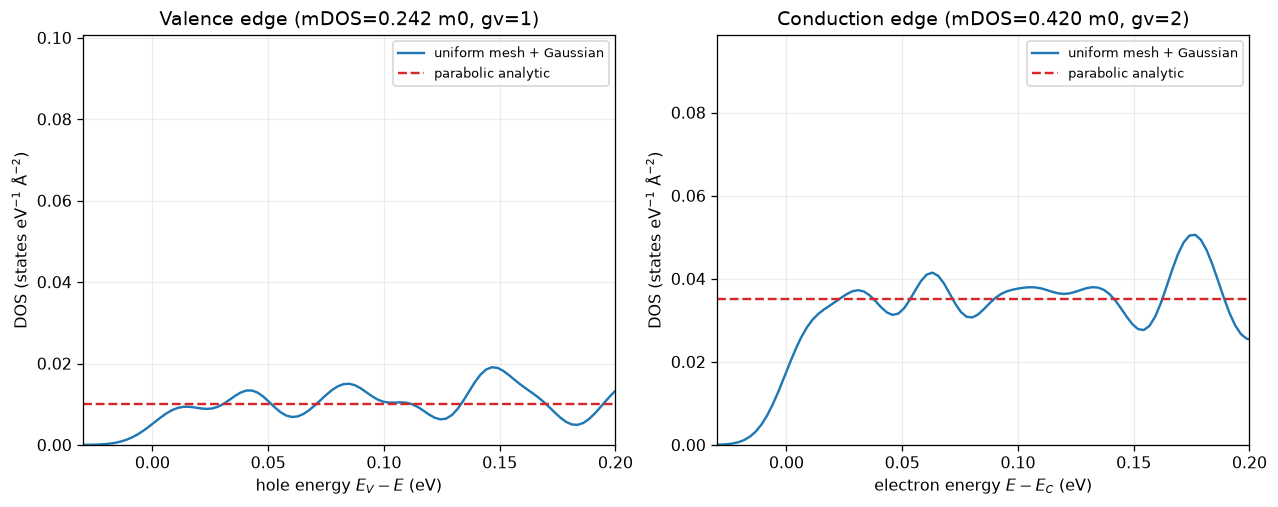

In [15]:
energy_values = energy_grid.magnitude
v_fit = fits[("valence", reported_radius)]
c_fit = fits[("conduction", reported_radius)]
v_dos_mass = float(np.sqrt(np.prod(v_fit["masses_m0"])))
c_dos_mass = float(np.sqrt(np.prod(c_fit["masses_m0"])))
analytic_v = spin_degeneracy * 1.0 * v_dos_mass / (2*np.pi*HBAR2_OVER_M0_EV_A2)
analytic_c = spin_degeneracy * 2.0 * c_dos_mass / (2*np.pi*HBAR2_OVER_M0_EV_A2)

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.3), constrained_layout=True)
axes[0].plot(valence_edge_ev-energy_values, valence_dos.density_of_states.magnitude,
             label="uniform mesh + Gaussian")
axes[0].axhline(analytic_v, color="C3", ls="--", label="parabolic analytic")
axes[0].set_xlim(-0.03, 0.20)
axes[0].set(xlabel=r"hole energy $E_V-E$ (eV)",
            ylabel=r"DOS (states eV$^{-1}$ Å$^{-2}$)",
            title=f"Valence edge (mDOS={v_dos_mass:.3f} m0, gv=1)")
axes[1].plot(energy_values-conduction_edge_ev, conduction_dos.density_of_states.magnitude,
             label="uniform mesh + Gaussian")
axes[1].axhline(analytic_c, color="C3", ls="--", label="parabolic analytic")
axes[1].set_xlim(-0.03, 0.20)
axes[1].set(xlabel=r"electron energy $E-E_C$ (eV)",
            ylabel=r"DOS (states eV$^{-1}$ Å$^{-2}$)",
            title=f"Conduction edge (mDOS={c_dos_mass:.3f} m0, gv=2)")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)


### DOS interpretation

- **Finite mesh spacing** discretizes each constant-energy contour, producing oscillations near the edge.
- **Gaussian broadening** rounds the ideal step and creates a small tail below the numerical edge.
- **Finite bandwidth** forces the numerical DOS to depart from a constant far from the edge.
- **Additional sheets/valleys** must be included explicitly. Here the two folded conduction sheets supply $g_v=2$; counting only sorted band 3 would undercount states and does not define a smooth Hessian.
- **Nonparabolicity** is visible in the fit-window mass drift and in departure from the analytic plateau as energy increases.


## 6. Fermi–Dirac occupation and intrinsic chemical potential

At finite temperature the correct quantity is the **chemical potential** $\mu(T)$ (also called the Fermi level), not the zero-temperature Fermi energy. For the complete two-band valence manifold and the represented conduction bands,

$$
n_{2D}(\mu,T)=w\sum_{\mathbf k,c}f(E_c,\mu,T),\qquad
p_{2D}(\mu,T)=w\sum_{\mathbf k,v}[1-f(E_v,\mu,T)],
$$

where $w=g_sA_{BZ}/[(2\pi)^2N_k]$. Numerically stable logistic forms are used for both electrons and holes, and intrinsic neutrality is solved with a bracketed Brent root:

$$n_{2D}(\mu_i,T)-p_{2D}(\mu_i,T)=0.$$

These are **sheet densities**. The conversion is $1\ \text{Å}^{-2}=10^{16}\ \text{cm}^{-2}$. This idealized result must not be interpreted as a bulk concentration.


In [16]:
K_B_EV = Boltzmann / electron_volt
state_weight_per_angstrom2 = valence_dos.request.sample_state_density.magnitude


def stable_fermi(energy_ev, chemical_potential_ev, temperature_k):
    """Stable f(E, mu, T), avoiding overflow in exp."""
    argument = (energy_ev - chemical_potential_ev) / (K_B_EV * temperature_k)
    positive = argument >= 0
    result = np.empty_like(np.asarray(argument, dtype=float))
    result[positive] = np.exp(-argument[positive]) / (1.0 + np.exp(-argument[positive]))
    result[~positive] = 1.0 / (1.0 + np.exp(argument[~positive]))
    return result


def carrier_densities_2d(chemical_potential_ev, temperature_k):
    # All two filled valence bands and all four represented conduction bands.
    valence_energy = full_zone_bands_ev[:, :2]
    conduction_energy = full_zone_bands_ev[:, 2:]
    electrons = state_weight_per_angstrom2 * np.sum(
        stable_fermi(conduction_energy, chemical_potential_ev, temperature_k)
    )
    # 1-f(E,mu,T) evaluated directly as f(mu,E,T), avoiding cancellation.
    holes = state_weight_per_angstrom2 * np.sum(
        stable_fermi(-valence_energy, -chemical_potential_ev, temperature_k)
    )
    return float(electrons), float(holes)


def intrinsic_state_2d(temperature_k):
    thermal_energy_ev = K_B_EV * temperature_k

    def neutrality(chemical_potential_ev):
        electrons, holes = carrier_densities_2d(chemical_potential_ev, temperature_k)
        return electrons - holes

    bracket = (
        valence_edge_ev - 40.0 * thermal_energy_ev,
        conduction_edge_ev + 40.0 * thermal_energy_ev,
    )
    chemical_potential_ev = brentq(
        neutrality, *bracket, xtol=5e-15, rtol=1e-14
    )
    electrons, holes = carrier_densities_2d(chemical_potential_ev, temperature_k)
    density_scale = max(electrons, holes, np.finfo(float).tiny)
    return {
        "temperature (K)": float(temperature_k),
        "mu_i (eV)": chemical_potential_ev,
        "n_2D (cm^-2)": electrons * 1e16,
        "p_2D (cm^-2)": holes * 1e16,
        "relative neutrality residual": abs(electrons - holes) / density_scale,
        "bracket lower (eV)": bracket[0],
        "bracket upper (eV)": bracket[1],
    }


room_temperature_state = intrinsic_state_2d(300.0)
pd.Series(room_temperature_state, name="full-band intrinsic state at 300 K")


temperature (K)                         300
mu_i (eV)                          3.141325
n_2D (cm^-2)                   1.534605e+10
p_2D (cm^-2)                   1.534605e+10
relative neutrality residual   1.338491e-14
bracket lower (eV)                 1.973944
bracket upper (eV)                  4.34046
Name: full-band intrinsic state at 300 K, dtype: float64

### Independent nondegenerate parabolic comparison

Because a constant 2D parabolic DOS integrates analytically,

$$N_C^{2D}=g_{c,2D}k_BT,\qquad N_V^{2D}=g_{v,2D}k_BT,$$

$$n_i^{2D}=\sqrt{N_C^{2D}N_V^{2D}}\exp[-E_g/(2k_BT)],$$

$$\mu_i^{MB}=\frac{E_C+E_V}{2}+\frac{k_BT}{2}\ln\!\left(\frac{N_V^{2D}}{N_C^{2D}}\right).$$

This is an independent local effective-mass oracle. Differences from the sampled full-band result arise from mesh quadrature, nonparabolicity, finite bandwidth, and the Boltzmann approximation.


In [17]:
def full_band_nondegenerate_densities_2d(temperature_k):
    """Boltzmann density scales obtained directly from every sampled band."""
    thermal_energy_ev = K_B_EV * temperature_k
    nc = state_weight_per_angstrom2 * np.sum(
        np.exp(-(full_zone_bands_ev[:, 2:] - conduction_edge_ev) / thermal_energy_ev)
    )
    nv = state_weight_per_angstrom2 * np.sum(
        np.exp(-(valence_edge_ev - full_zone_bands_ev[:, :2]) / thermal_energy_ev)
    )
    return {
        "Nc_full_band (cm^-2)": nc * 1e16,
        "Nv_full_band (cm^-2)": nv * 1e16,
    }


def parabolic_intrinsic_state_2d(temperature_k):
    thermal_energy_ev = K_B_EV * temperature_k
    nc = analytic_c * thermal_energy_ev
    nv = analytic_v * thermal_energy_ev
    ni = np.sqrt(nc * nv) * np.exp(-band_gap_ev / (2.0 * thermal_energy_ev))
    mu = (0.5 * (conduction_edge_ev + valence_edge_ev)
          + 0.5 * thermal_energy_ev * np.log(nv / nc))
    return {
        "Nc_2D (cm^-2)": nc * 1e16,
        "Nv_2D (cm^-2)": nv * 1e16,
        "mu_i_MB (eV)": mu,
        "ni_2D_MB (cm^-2)": ni * 1e16,
    }


temperatures_k = np.linspace(150.0, 600.0, 31)
carrier_rows = []
for temperature in temperatures_k:
    exact = intrinsic_state_2d(temperature)
    approximate = parabolic_intrinsic_state_2d(temperature)
    full_band_scales = full_band_nondegenerate_densities_2d(temperature)
    carrier_rows.append({**exact, **approximate, **full_band_scales})
carrier_table = pd.DataFrame(carrier_rows)

selected_temperature_table = carrier_table[
    np.isclose(carrier_table["temperature (K)"].to_numpy()[:, None],
               np.array([150.0, 300.0, 450.0, 600.0])[None, :]).any(axis=1)
].copy()
selected_temperature_table["MB/exact density"] = (
    selected_temperature_table["ni_2D_MB (cm^-2)"] /
    selected_temperature_table["n_2D (cm^-2)"]
)
selected_temperature_table[
    ["temperature (K)", "Nc_2D (cm^-2)", "Nv_2D (cm^-2)",
     "Nc_full_band (cm^-2)", "Nv_full_band (cm^-2)",
     "mu_i (eV)", "mu_i_MB (eV)", "n_2D (cm^-2)",
     "p_2D (cm^-2)", "ni_2D_MB (cm^-2)", "MB/exact density",
     "relative neutrality residual"]
]


,temperature (K),Nc_2D (cm^-2),Nv_2D (cm^-2),Nc_full_band (cm^-2),Nv_full_band (cm^-2),mu_i (eV),mu_i_MB (eV),n_2D (cm^-2),p_2D (cm^-2),ni_2D_MB (cm^-2),MB/exact density,relative neutrality residual
0,150,4.534375e+12,1.308055e+12,4.534841e+12,1.315497e+12,3.149204,3.149168,2.374951e+07,2.374951e+07,2.368116e+07,0.9971219,1.393175e-14
10,300,9.06875e+12,2.61611e+12,9.102647e+12,2.670479e+12,3.141325,3.141133,1.534605e+10,1.534605e+10,1.518859e+10,0.9897389,1.338491e-14
20,450,1.360313e+13,3.924164e+12,1.370296e+13,4.065886e+12,3.133388,3.133099,1.573621e+11,1.573621e+11,1.559445e+11,0.9909916,8.612321e-16
30,600,1.81375e+13,5.232219e+12,1.833536e+13,5.502698e+12,3.125221,3.125064,5.435119e+11,5.435119e+11,5.439882e+11,1.000876,5.784945e-14


### Building $N_C^{2D}$ and $N_V^{2D}$ from their component pieces

At a reference temperature, each parabolic edge component contributes

$$
N_j^{2D}=
\underbrace{g_s}_{\text{spin}}
\underbrace{g_{v,j}}_{\text{equivalent sheets}}
\underbrace{\frac{\sqrt{m_{1,j}m_{2,j}}}{m_0}}
_{m_{d,2D}/m_0}
\underbrace{\frac{k_BT}{2\pi(\hbar^2/m_0)}}
_{\text{thermal state scale}}.
$$

The two conduction sheets are listed separately before they are summed. This makes spin, sheet degeneracy, principal masses, DOS mass, DOS plateau, and thermal energy auditable. These $N_C^{2D}$ and $N_V^{2D}$ values are in cm$^{-2}$, not the three-dimensional effective densities of states used for a bulk semiconductor.

The full-zone band-index decomposition is diagnostic only: because PhysKit sorts eigenvalues, bands 3 and 4 exchange smooth-sheet identity across quadrants. Their individual sampled totals need not be equal; their **sum** is the quantity comparable with the two equal analytic sheet contributions.


In [18]:
reference_temperature_k = 300.0
thermal_energy_300_ev = K_B_EV * reference_temperature_k
conduction_per_sheet_dos = (
    spin_degeneracy * c_dos_mass / (2*np.pi*HBAR2_OVER_M0_EV_A2)
)
valence_component_dos = (
    spin_degeneracy * v_dos_mass / (2*np.pi*HBAR2_OVER_M0_EV_A2)
)

component_rows = [
    {"edge component": "conduction sheet A", "g_s": spin_degeneracy, "g_v": 1,
     "m1/m0": c_fit["masses_m0"][0], "m2/m0": c_fit["masses_m0"][1],
     "m_d,2D/m0": c_dos_mass, "DOS plateau (eV^-1 A^-2)": conduction_per_sheet_dos,
     "kBT (eV)": thermal_energy_300_ev,
     "N component (cm^-2)": conduction_per_sheet_dos * thermal_energy_300_ev * 1e16},
    {"edge component": "conduction sheet B", "g_s": spin_degeneracy, "g_v": 1,
     "m1/m0": c_fit["masses_m0"][1], "m2/m0": c_fit["masses_m0"][0],
     "m_d,2D/m0": c_dos_mass, "DOS plateau (eV^-1 A^-2)": conduction_per_sheet_dos,
     "kBT (eV)": thermal_energy_300_ev,
     "N component (cm^-2)": conduction_per_sheet_dos * thermal_energy_300_ev * 1e16},
    {"edge component": "valence band 2", "g_s": spin_degeneracy, "g_v": 1,
     "m1/m0": v_fit["masses_m0"][0], "m2/m0": v_fit["masses_m0"][1],
     "m_d,2D/m0": v_dos_mass, "DOS plateau (eV^-1 A^-2)": valence_component_dos,
     "kBT (eV)": thermal_energy_300_ev,
     "N component (cm^-2)": valence_component_dos * thermal_energy_300_ev * 1e16},
]
effective_density_components = pd.DataFrame(component_rows)
nc_from_components = effective_density_components.loc[
    effective_density_components["edge component"].str.startswith("conduction"),
    "N component (cm^-2)",
].sum()
nv_from_components = effective_density_components.loc[
    effective_density_components["edge component"].str.startswith("valence"),
    "N component (cm^-2)",
].sum()

effective_density_components


,edge component,g_s,g_v,m1/m0,m2/m0,"m_d,2D/m0",DOS plateau (eV^-1 A^-2),kBT (eV),N component (cm^-2)
0,conduction sheet A,2,1,1.078804,0.1634217,0.4198809,0.01753975,0.025852,4.534375e+12
1,conduction sheet B,2,1,0.1634217,1.078804,0.4198809,0.01753975,0.025852,4.534375e+12
2,valence band 2,2,1,0.2422504,0.2422504,0.2422504,0.01011956,0.025852,2.61611e+12


In [19]:
# Independent full-zone Boltzmann contributions, resolved by represented band.
band_component_rows = []
for band_index in range(2, band_count):
    contribution = state_weight_per_angstrom2 * np.sum(
        np.exp(-(full_zone_bands_ev[:, band_index] - conduction_edge_ev)
               / thermal_energy_300_ev)
    ) * 1e16
    band_component_rows.append({
        "density scale": "Nc_full_band", "band (1-based)": band_index + 1,
        "component (cm^-2)": contribution,
    })
for band_index in range(2):
    contribution = state_weight_per_angstrom2 * np.sum(
        np.exp(-(valence_edge_ev - full_zone_bands_ev[:, band_index])
               / thermal_energy_300_ev)
    ) * 1e16
    band_component_rows.append({
        "density scale": "Nv_full_band", "band (1-based)": band_index + 1,
        "component (cm^-2)": contribution,
    })
full_band_component_table = pd.DataFrame(band_component_rows)
full_band_component_table["fraction of scale"] = full_band_component_table.groupby(
    "density scale"
)["component (cm^-2)"].transform(lambda values: values / values.sum())

summary_nc_nv = pd.DataFrame([
    {"quantity": "Nc_2D parabolic", "value (cm^-2)": nc_from_components,
     "construction": "sheet A + sheet B from fitted masses"},
    {"quantity": "Nv_2D parabolic", "value (cm^-2)": nv_from_components,
     "construction": "valence band 2 from fitted hole masses"},
    {"quantity": "Nc_2D full-band Boltzmann", "value (cm^-2)":
     full_band_component_table.loc[full_band_component_table["density scale"] == "Nc_full_band",
                                   "component (cm^-2)"].sum(),
     "construction": "sampled bands 3-6"},
    {"quantity": "Nv_2D full-band Boltzmann", "value (cm^-2)":
     full_band_component_table.loc[full_band_component_table["density scale"] == "Nv_full_band",
                                   "component (cm^-2)"].sum(),
     "construction": "sampled bands 1-2"},
])
display(summary_nc_nv)
full_band_component_table


,quantity,value (cm^-2),construction
0,Nc_2D parabolic,9.06875e+12,sheet A + sheet B from fitted masses
1,Nv_2D parabolic,2.61611e+12,valence band 2 from fitted hole masses
2,Nc_2D full-band Boltzmann,9.102647e+12,sampled bands 3-6
3,Nv_2D full-band Boltzmann,2.670479e+12,sampled bands 1-2


,density scale,band (1-based),component (cm^-2),fraction of scale
0,Nc_full_band,3,6.794043e+12,0.746381
1,Nc_full_band,4,2.308605e+12,0.253619
2,Nc_full_band,5,3.101902e-38,3.407692e-51
3,Nc_full_band,6,9.23372e-39,1.014399e-51
4,Nv_full_band,1,1.270587e-16,4.757901e-29
5,Nv_full_band,2,2.670479e+12,1


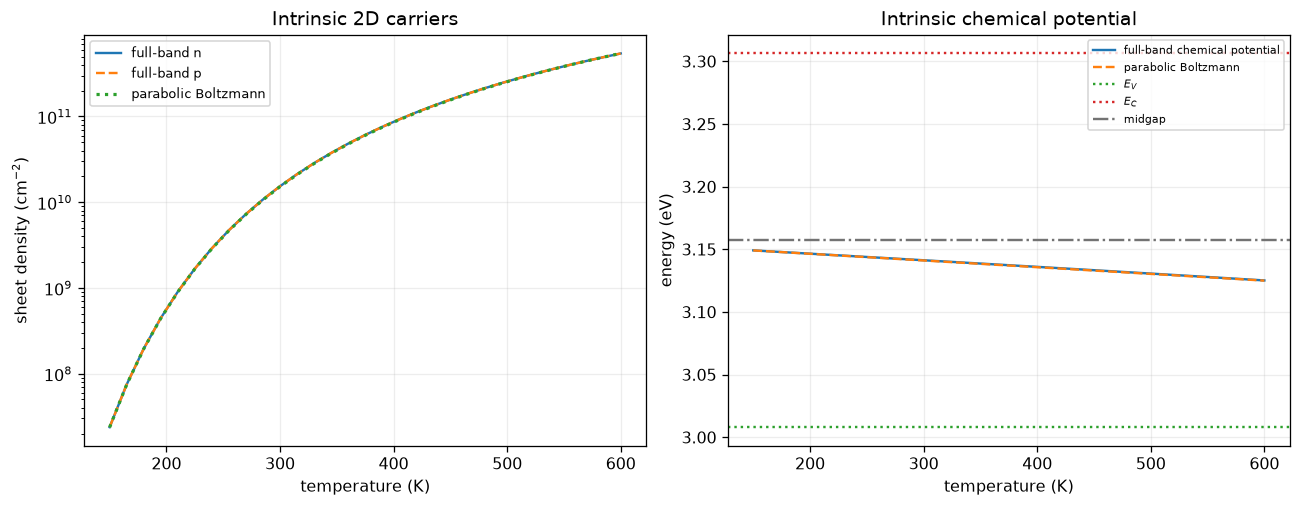

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3), constrained_layout=True)
axes[0].semilogy(carrier_table["temperature (K)"], carrier_table["n_2D (cm^-2)"],
                 label="full-band n")
axes[0].semilogy(carrier_table["temperature (K)"], carrier_table["p_2D (cm^-2)"],
                 "--", label="full-band p")
axes[0].semilogy(carrier_table["temperature (K)"], carrier_table["ni_2D_MB (cm^-2)"],
                 ":", lw=2, label="parabolic Boltzmann")
axes[0].set(xlabel="temperature (K)", ylabel=r"sheet density (cm$^{-2}$)",
            title="Intrinsic 2D carriers")
axes[0].legend(fontsize=8)

axes[1].plot(carrier_table["temperature (K)"], carrier_table["mu_i (eV)"],
             label="full-band chemical potential")
axes[1].plot(carrier_table["temperature (K)"], carrier_table["mu_i_MB (eV)"],
             "--", label="parabolic Boltzmann")
axes[1].axhline(valence_edge_ev, color="C2", ls=":", label=r"$E_V$")
axes[1].axhline(conduction_edge_ev, color="C3", ls=":", label=r"$E_C$")
axes[1].axhline(0.5*(valence_edge_ev+conduction_edge_ev), color="0.45", ls="-.",
                label="midgap")
axes[1].set(xlabel="temperature (K)", ylabel="energy (eV)",
            title="Intrinsic chemical potential")
axes[1].legend(fontsize=7)


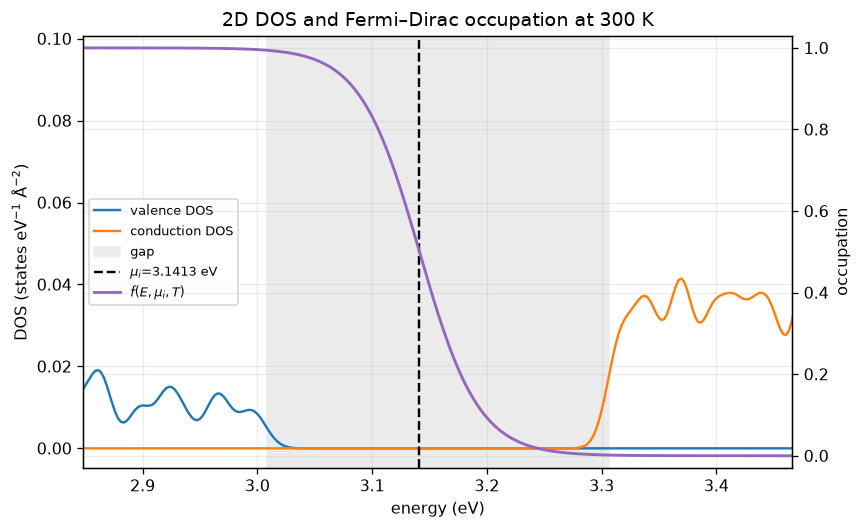

In [21]:
# DOS and Fermi occupation at 300 K. Occupation uses a separate right axis.
mu_300 = room_temperature_state["mu_i (eV)"]
f_300 = stable_fermi(energy_values, mu_300, 300.0)
fig, ax_dos = plt.subplots(figsize=(7.6, 4.7))
ax_dos.plot(energy_values, valence_dos.density_of_states.magnitude,
            label="valence DOS")
ax_dos.plot(energy_values, conduction_dos.density_of_states.magnitude,
            label="conduction DOS")
ax_dos.axvspan(valence_edge_ev, conduction_edge_ev, color="0.92", label="gap")
ax_dos.axvline(mu_300, color="k", ls="--", label=rf"$\mu_i$={mu_300:.4f} eV")
ax_dos.set_xlim(valence_edge_ev-0.16, conduction_edge_ev+0.16)
ax_dos.set(xlabel="energy (eV)",
           ylabel=r"DOS (states eV$^{-1}$ Å$^{-2}$)",
           title="2D DOS and Fermi–Dirac occupation at 300 K")
ax_occ = ax_dos.twinx()
ax_occ.plot(energy_values, f_300, color="C4", lw=1.8, label=r"$f(E,\mu_i,T)$")
ax_occ.set(ylabel="occupation", ylim=(-0.03, 1.03))
lines_1, labels_1 = ax_dos.get_legend_handles_labels()
lines_2, labels_2 = ax_occ.get_legend_handles_labels()
ax_dos.legend(lines_1 + lines_2, labels_1 + labels_2, fontsize=8, loc="center left")
fig.tight_layout()


### “Fermi energy” at zero temperature

For this intrinsic gapped model, every $\mu$ strictly inside the gap produces the same $T=0$ occupations: both valence bands are full and the conduction bands are empty. State counting alone therefore does not select a unique in-gap Fermi energy. The intrinsic finite-temperature neutrality solution is well-defined; in the parabolic model its $T\rightarrow0$ limit approaches midgap because the DOS-asymmetry correction is proportional to $T$. Report $\mu(T)$ with its temperature rather than quoting an ambiguous finite-temperature “Fermi energy.”


## 7. Automated acceptance checks and conclusion

The checks below fail loudly if Hermiticity, edge character, tensor signs, state normalization, or the reported local-fit quality is lost.


In [22]:
checks = {
    "Hamiltonian Hermitian": hermiticity_residual < 1e-13,
    "complete band gap positive": band_gap_ev > 0,
    "conduction doublet degenerate at edge": np.ptp(conduction_pair_at_edge) < 2e-6,
    "all positive valence hole curvatures": np.all(v_fit["curvatures"] > 0),
    "all positive conduction curvatures": np.all(c_fit["curvatures"] > 0),
    "valence local max residual < 0.1 meV": 1e3*v_fit["max_error_ev"] < 0.1,
    "conduction local max residual < 0.1 meV": 1e3*c_fit["max_error_ev"] < 0.1,
    "valence DOS state count within 0.5%": abs(state_count_table.iloc[0]["integral relative error"]) < 5e-3,
    "conduction DOS state count within 0.5%": abs(state_count_table.iloc[1]["integral relative error"]) < 5e-3,
    "Nc equals sum of conduction components": np.isclose(
        nc_from_components, parabolic_intrinsic_state_2d(300.0)["Nc_2D (cm^-2)"], rtol=1e-13
    ),
    "Nv equals sum of valence components": np.isclose(
        nv_from_components, parabolic_intrinsic_state_2d(300.0)["Nv_2D (cm^-2)"], rtol=1e-13
    ),
    "n increases with chemical potential": (
        carrier_densities_2d(mu_300 + 0.01, 300.0)[0]
        > carrier_densities_2d(mu_300 - 0.01, 300.0)[0]
    ),
    "p decreases with chemical potential": (
        carrier_densities_2d(mu_300 + 0.01, 300.0)[1]
        < carrier_densities_2d(mu_300 - 0.01, 300.0)[1]
    ),
    "intrinsic neutrality residual < 1e-10": (
        carrier_table["relative neutrality residual"].max() < 1e-10
    ),
    "chemical potential remains in gap": (
        (carrier_table["mu_i (eV)"] > valence_edge_ev).all()
        and (carrier_table["mu_i (eV)"] < conduction_edge_ev).all()
    ),
    "M=3 to M=4 gap change < 0.1 meV": abs(
        basis_convergence.iloc[-1]["Eg (eV)"] - basis_convergence.iloc[-2]["Eg (eV)"]
    ) < 1e-4,
}
validation_table = pd.DataFrame(
    [{"check": name, "passed": bool(passed)} for name, passed in checks.items()]
)
assert validation_table["passed"].all(), validation_table
validation_table


,check,passed
0,Hamiltonian Hermitian,True
1,complete band gap positive,True
2,conduction doublet degenerate at edge,True
3,all positive valence hole curvatures,True
4,all positive conduction curvatures,True
5,valence local max residual < 0.1 meV,True
6,conduction local max residual < 0.1 meV,True
7,valence DOS state count within 0.5%,True
8,conduction DOS state count within 0.5%,True
9,Nc equals sum of conduction components,True


In [23]:
summary = pd.Series({
    "Ev (eV)": valence_edge_ev,
    "Ec (eV)": conduction_edge_ev,
    "gap (eV)": band_gap_ev,
    "valence m1, m2 (m0)": tuple(v_fit["masses_m0"]),
    "conduction sheet m1, m2 (m0)": tuple(c_fit["masses_m0"]),
    "valence mDOS (m0)": v_dos_mass,
    "conduction per-sheet mDOS (m0)": c_dos_mass,
    "conduction sheet degeneracy": 2,
    "reported fit radius (1/angstrom)": reported_radius,
    "valence sampled fit window (meV)": 1e3*v_fit["energy_window_ev"],
    "conduction sampled fit window (meV)": 1e3*c_fit["energy_window_ev"],
}, name="Part I result")
summary


Ev (eV)                                                                 3.008024
Ec (eV)                                                                  3.30638
gap (eV)                                                               0.2983565
valence m1, m2 (m0)                    (0.24225044894997033, 0.2422504489498705)
conduction sheet m1, m2 (m0)            (1.0788036058985655, 0.1634217336621736)
valence mDOS (m0)                                                      0.2422504
conduction per-sheet mDOS (m0)                                         0.4198809
conduction sheet degeneracy                                                    2
reported fit radius (1/angstrom)                                            0.03
valence sampled fit window (meV)                                        14.20829
conduction sampled fit window (meV)                                     20.60402
Name: Part I result, dtype: object

**Conclusion.** The effective-mass approximation is quantitatively local. The $r=0.03$ Å$^{-1}$ fits sample the energy windows printed above and keep the maximum two-dimensional regression error below 0.1 meV. At $r=0.06$ and $0.10$ Å$^{-1}$, the increasing residual and systematic mass drift show physical nonparabolicity rather than a hidden path-sampling error. The analytic 2D DOS is therefore defensible only in the near-edge window where the curvature has converged; the full-zone PhysKit DOS must be used outside it.

The checkerboard calculation validates curvature extraction, degeneracy bookkeeping, and two-dimensional state counting. It does **not** provide a three-dimensional DOS, real-material effective masses, dopant model, or transport properties.
